# Anisotropic Diffusion

**Seong Cho** · ACME Volume 4, Lab 9

**Lab objective:** demonstrate the use of finite difference schemes in image analysis by denoising black and white and color images with anisotropic (Perona-Malik) diffusion.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
from matplotlib import cm, pyplot as plt
# from scipy.misc import imsave    # [compat]: scipy.misc.imsave was removed (and isn't used)
from imageio.v2 import imread    # [compat]: the top-level imageio.imread is deprecated
from numpy.random import randint
plt.rcParams['figure.dpi'] = 72    # Changed: the old inline default resolution, keeps the large image figures small

## Diffusion in images

Blurring an image removes static, and blurring is what the heat equation $u_t = c\Delta u$ does on a rectangular domain, but it also blurs the boundaries between distinct elements of the image. The more general diffusion equation

$$u_t = \nabla\cdot\big(c(x,y,t)\nabla u\big)$$

lets the diffusion coefficient $c$ vary, so it can be made small across edges and large elsewhere: static blurs away while boundaries stay sharp. This is **Anisotropic Diffusion** (or Perona-Malik Diffusion), first introduced by Pietro Perona and Jitendra Malik in 1987.

## A finite difference scheme

If $E$ estimates the rate of change at each point (largest at the boundaries), take $c(x,y,t) = g(E(x,y,t))$ with $g(0) = 1$ and $\lim_{x\to\infty} g(x) = 0$. Let $U^n_{l,m}$ approximate $u$ at time index $n$ and pixel $(l, m)$. With pixel spacing $\Delta x = \Delta y = 1$ and $\Delta t = 1$, the five-point Laplacian gives the update $U^{n+1}_{l,m} = U^n_{l,m} + \sum (U^n_{\text{neighbor}} - U^n_{l,m})$ over the four neighbors, and limiting diffusion near edges gives

$$U^{n+1}_{l,m} = U^n_{l,m} + \lambda\Big(g(|U^n_{l-1,m} - U^n_{l,m}|)(U^n_{l-1,m} - U^n_{l,m}) + g(|U^n_{l+1,m} - U^n_{l,m}|)(U^n_{l+1,m} - U^n_{l,m})$$
$$\qquad\qquad + g(|U^n_{l,m-1} - U^n_{l,m}|)(U^n_{l,m-1} - U^n_{l,m}) + g(|U^n_{l,m+1} - U^n_{l,m}|)(U^n_{l,m+1} - U^n_{l,m})\Big),$$

where $\lambda \le \frac14$ is the stability condition. Each pixel is affected most by similar neighbors, and since each point's effect on a neighbor is the opposite of the neighbor's effect on it, the total brightness is unchanged. Common choices are $g(x) = e^{-(x/\sigma)^2}$ and $g(x) = 1/(1 + (x/\sigma)^2)$, where larger $\sigma$ allows more diffusion across boundaries; this lab uses $g(x) = e^{-(x/\sigma)^2}$. (This scheme isn't an accurate finite difference scheme for the PDE above; it solves a slightly different diffusion PDE but does the same job.)

Images are read with `imageio.imread` and scaled to floats in $[0, 1]$; `as_gray=True` converts to black and white.

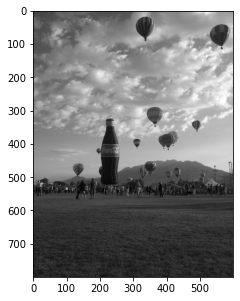

In [2]:
from matplotlib import cm, pyplot as plt
from imageio.v2 import imread    # [compat]
# To read in an image, convert it to grayscale, and rescale it.
picture = imread('balloon.jpg', mode='F') * 1./255    # [compat]: as_gray=True is no longer supported; mode='F' gives the same grayscale floats
# To display the picture as grayscale
plt.imshow(picture, cmap=cm.gray)
plt.show()

## Problem 1: Black and white images

> **Problem 1.** Complete the following function, implementing anisotropic diffusion for black and white images using the following boundary conditions: for the top edge let
>
> $$U^{n+1}_{l,m} = U^n_{l,m} + \lambda\Big(g(|U^n_{l-1,m} - U^n_{l,m}|)(U^n_{l-1,m} - U^n_{l,m}) + g(|U^n_{l+1,m} - U^n_{l,m}|)(U^n_{l+1,m} - U^n_{l,m}) + g(|U^n_{l,m+1} - U^n_{l,m}|)(U^n_{l,m+1} - U^n_{l,m})\Big).$$
>
> Do the other edges similarly. For the top left corner let
>
> $$U^{n+1}_{l,m} = U^n_{l,m} + \lambda\Big(g(|U^n_{l+1,m} - U^n_{l,m}|)(U^n_{l+1,m} - U^n_{l,m}) + g(|U^n_{l,m+1} - U^n_{l,m}|)(U^n_{l,m+1} - U^n_{l,m})\Big).$$
>
> Do the other corners similarly. Essentially we are just using the terms of the difference scheme that are actually defined. In your function, use $g(x) = e^{-(x/\sigma)^2}$.
>
> ```python
> def anisdiff_bw(U, N, lambda_, g):
>     """ Run the Anisotropic Diffusion differencing scheme
>     on the array U of grayscale values for an image.
>     Perform N iterations, use the function g
>     to limit diffusion across boundaries in the image.
>     Operate on U inplace to optimize performance. """
>     pass
> ```
>
> Run the function on `balloon.jpg`. Show the original image and the diffused image for $\sigma = .1$, $\lambda = .25$, $N = 5, 20, 100$.

In [3]:
def anisdiff_bw(U, N, lambda_, g):
    """ Run the Anisotropic Diffusion differencing scheme
    on the array U of grayscale values for an image.
    Perform N iterations, use the function g
    to limit diffusion across boundaries in the image.
    Operate on U inplace to optimize performance. """
    U1 = U.copy()
    for _ in range(N):
        U_ = np.pad(U1, 1, "edge")    # Changed: was zero padding; edge padding makes the missing edge/corner terms vanish, as the spec's boundary conditions require
        U0 = U_[1:-1,1:-1]
        A = U_[:-2,1:-1] - U0
        B = U_[2:,1:-1] - U0
        C = U_[1:-1,:-2] - U0
        D = U_[1:-1,2:] - U0
        U1 += lambda_ * (g(np.abs(A))*A
                       + g(np.abs(B))*B
                       + g(np.abs(C))*C
                       + g(np.abs(D))*D)
    return U1

In [4]:
lambda_ = .25
sigma = 0.1
g = lambda x: np.exp(-(x/sigma)**2)
U5 = anisdiff_bw(picture, 5, lambda_, g)
U20 = anisdiff_bw(picture, 20, lambda_, g)
U100 = anisdiff_bw(picture, 100, lambda_, g)

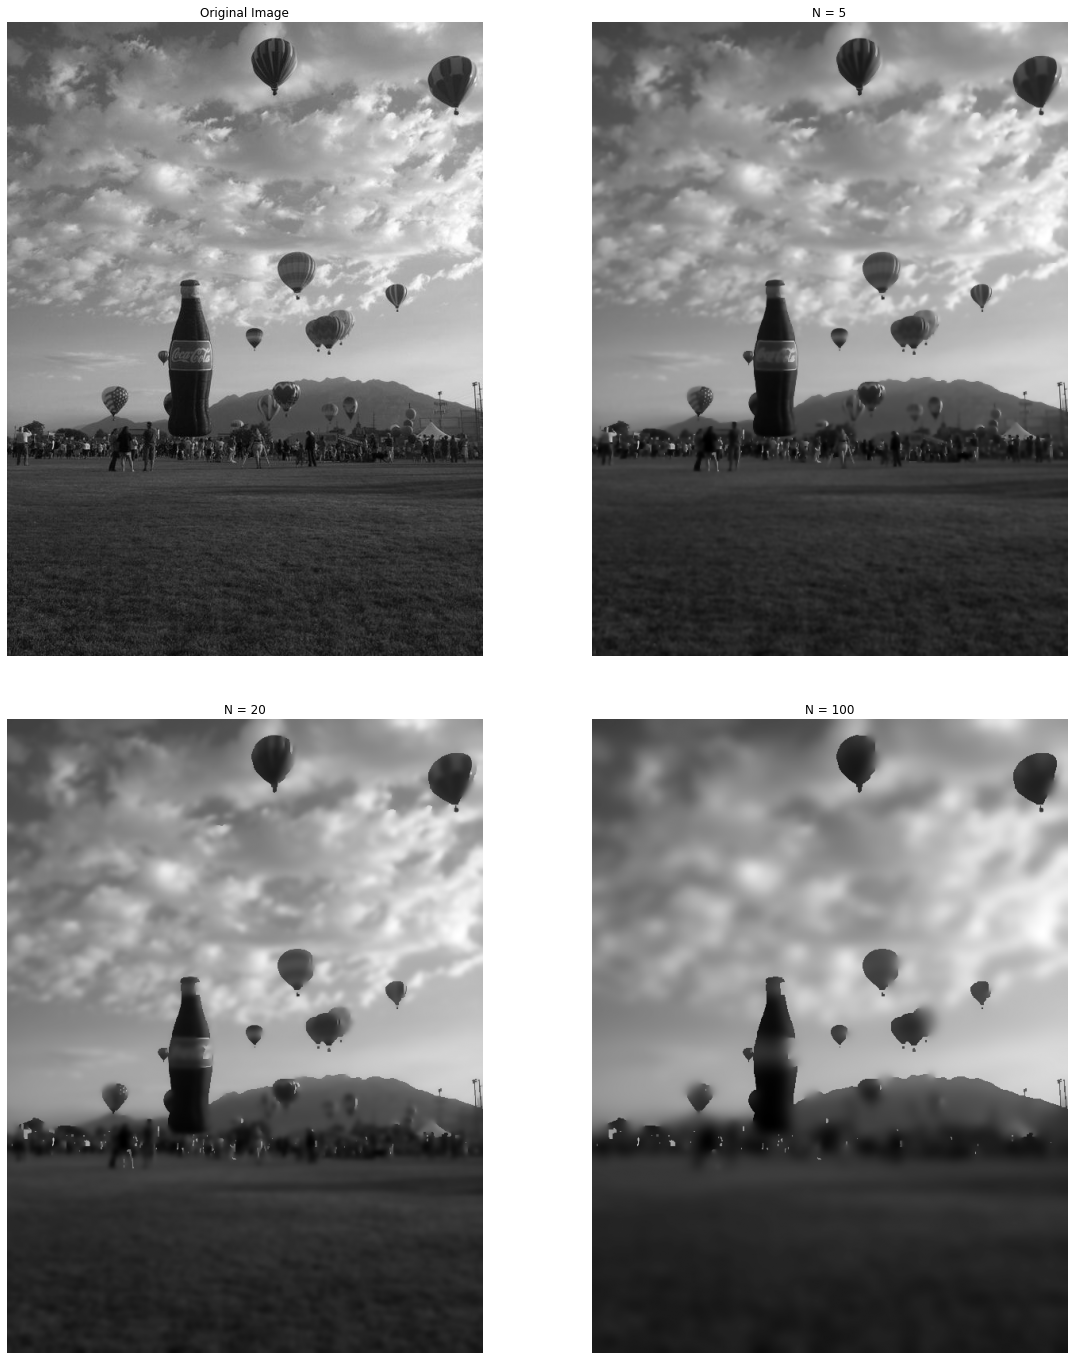

In [5]:
fig, ax = plt.subplots(2,2, figsize=(20,24))
ax[0, 0].axis("off")
ax[0, 0].imshow(picture, cmap=cm.gray)
ax[0, 0].set_title("Original Image")
ax[0, 1].axis("off")
ax[0, 1].imshow(U5, cmap=cm.gray)
ax[0, 1].set_title("N = 5")
ax[1, 0].axis("off")
ax[1, 0].imshow(U20, cmap=cm.gray)
ax[1, 0].set_title("N = 20")
ax[1, 1].axis("off")
ax[1, 1].imshow(U100, cmap=cm.gray)
ax[1, 1].set_title("N = 100")

plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.show()

In [6]:
print("total brightness before and after 100 iterations:", picture.sum(), U100.sum())

total brightness before and after 100 iterations: 213391.56 213391.55


## Color images

A color image is an $m \times n \times 3$ array of red, green and blue intensities. The same scheme runs on each color, but edges should be detected in any color, so $g(|U^n_{l+1,m} - U^n_{l,m}|)$ becomes $g(\|U^n_{l+1,m} - U^n_{l,m}\|)$ with the 2-norm on 3-space, $\|x\| = \sqrt{x_1^2 + x_2^2 + x_3^2}$, and the update is read as an equation on vectors.

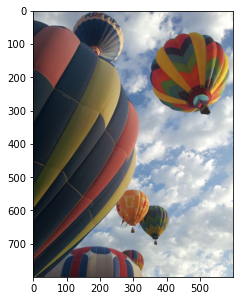

In [7]:
from matplotlib import cm, pyplot as plt
from imageio.v2 import imread    # [compat]
# To read in an image, convert it to grayscale, and rescale it.
picture = imread('balloons_color.jpg') * 1./255
# To display the picture as grayscale
plt.imshow(picture)
plt.show()

## Problem 2: Color images

> **Problem 2.** Complete the following function to process a colored image. You may modify your code from the previous problem. Measure the difference between pixels using the 2-norm. Use the corresponding vector versions of the boundary conditions given in Problem 1.
>
> ```python
> def anisdiff_color(U, N, lambda_, sigma):
>     """ Run the Anisotropic Diffusion differencing scheme
>     on the array U of grayscale values for an image.
>     Perform N iterations, use the function g = e^{-x^2/sigma^2}
>     to limit diffusion across boundaries in the image.
>     Operate on U inplace to optimize performance. """
>     pass
> ```
>
> Run the function on `balloons_color.jpg`. Show the original image and the diffused image for $\sigma = .1$, $\lambda = .25$, $N = 5, 20, 100$.
>
> Hint: If you have an $m\times n\times 3$ matrix representing the RGB differences of each pixel, then to find a matrix representing the norm of the differences, you can use the following code. This code squares each value and sums along the last axis, and takes the square root. In order to keep the dimension size of the matrix and aid in broadcasting, you must use `keepdims=True`.
>
> ```python
> # x is mxnx3 matrix of pixel color values
> norm = np.sqrt(np.sum(x**2, axis=2, keepdims=True))
> ```

In [8]:
def anisdiff_color(U, N, lambda_, sigma):
    """ Run the Anisotropic Diffusion differencing scheme
    on the array U of grayscale values for an image.
    Perform N iterations, use the function g = e^{-x^2/sigma^2}
    to limit diffusion across boundaries in the image.
    Operate on U inplace to optimize performance. """
    U1 = U.copy()
    npad = ((1, 1), (1, 1), (0, 0))
    norm = lambda x: np.sqrt(np.sum(x**2, axis=2, keepdims=True))
    for _ in range(N):
        U_ = np.pad(U1, npad, "edge")    # Changed: was zero padding; edge padding makes the missing edge/corner terms vanish, as the spec's boundary conditions require
        U0 = U_[1:-1,1:-1]
        A = U_[:-2,1:-1] - U0
        B = U_[2:,1:-1] - U0
        C = U_[1:-1,:-2] - U0
        D = U_[1:-1,2:] - U0
        U1 += lambda_ * (g(norm(A))*A
                       + g(norm(B))*B
                       + g(norm(C))*C
                       + g(norm(D))*D)
    return U1

In [9]:
lambda_ = .25
sigma = 0.1
g = lambda x: np.exp(-(x/sigma)**2)
U5 = anisdiff_color(picture, 5, lambda_, g)
U20 = anisdiff_color(picture, 20, lambda_, g)
U100 = anisdiff_color(picture, 100, lambda_, g)

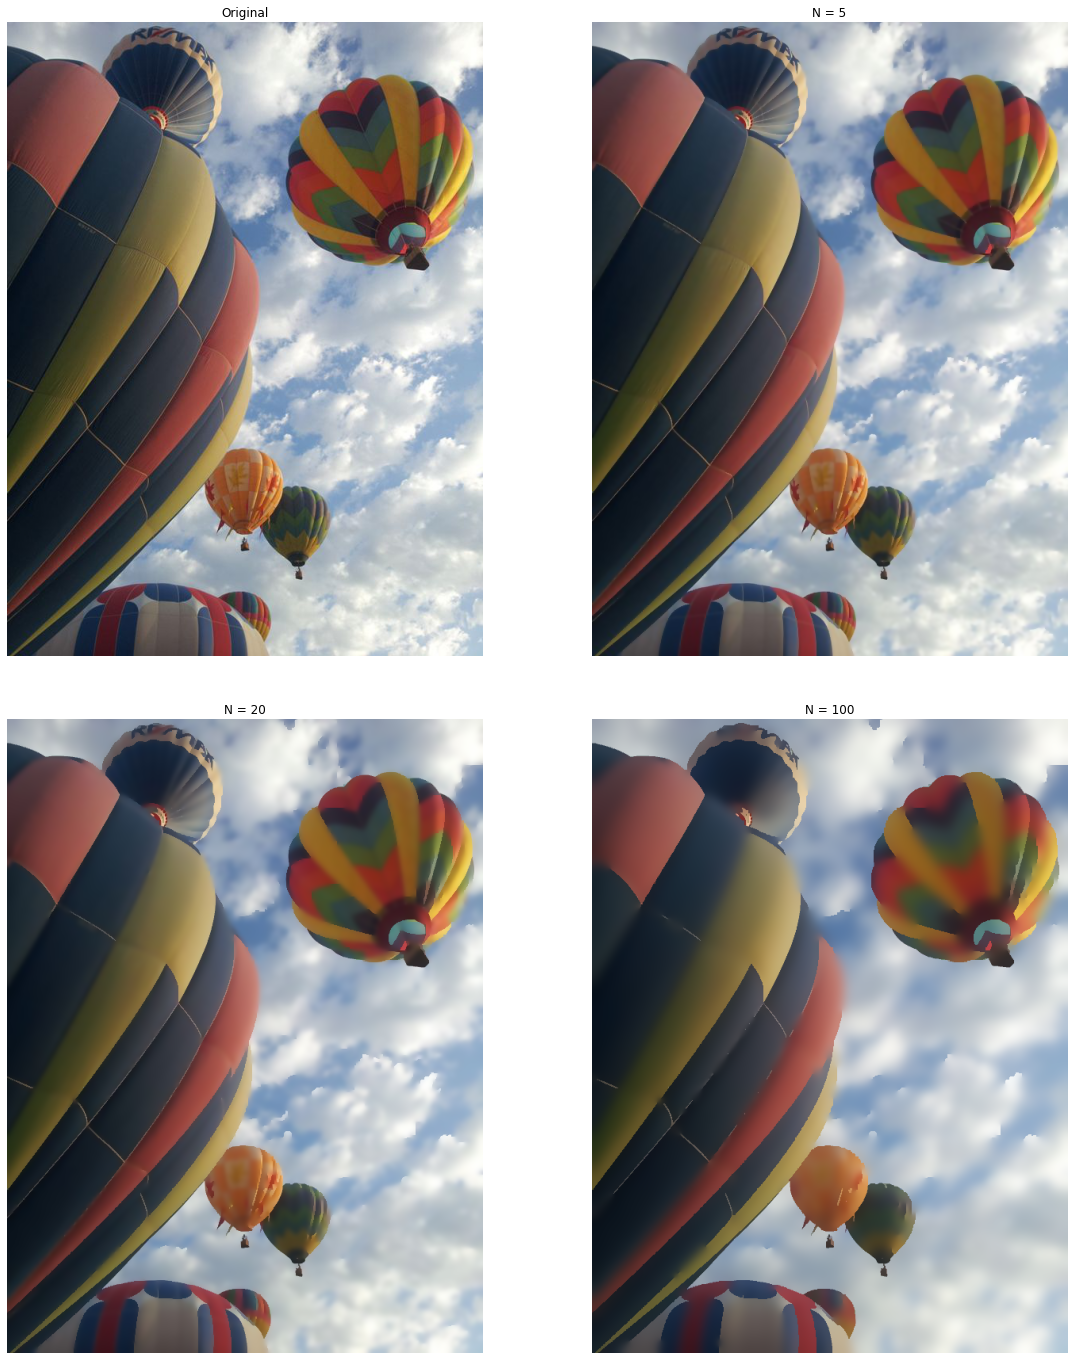

In [10]:
fig, ax = plt.subplots(2,2, figsize=(20,24))
ax[0, 0].axis("off")
ax[0, 0].imshow(picture)
ax[0, 0].set_title("Original")
ax[0, 1].axis("off")
ax[0, 1].imshow(U5)
ax[0, 1].set_title("N = 5")
ax[1, 0].axis("off")
ax[1, 0].imshow(U20)
ax[1, 0].set_title("N = 20")
ax[1, 1].axis("off")
ax[1, 1].imshow(U100)
ax[1, 1].set_title("N = 100")
plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.show()

## Problem 3: Noisy images

> **Problem 3.** Use the following code to add noise to your grayscale image.
>
> ```python
> from numpy.random import randint
> image = imread('balloon.jpg', as_gray=True)
> x, y = image.shape
> for i in xrange(x*y//100):
>     image[randint(x),randint(y)] = 127 + randint(127)
> ```
>
> Run `anisdiff_bw()` on the noisy image with $\sigma = .1$, $\lambda = .25$, $N = 20$. Display the original image and the noisy image. Explain why anisotropic diffusion does not smooth out the noise.
>
> Hint: Don't forget to rescale.

In [11]:
np.random.seed(0)    # Changed: seed the noise so reruns are reproducible
image = imread('balloon.jpg', mode='F')    # [compat]: as_gray=True is no longer supported
x, y = image.shape
for i in range(x*y//100):
    image[randint(x),randint(y)] = 127 + randint(127)
image *= 1./255

In [12]:
lambda_ = .25
sigma = 0.1
g = lambda x: np.exp(-(x/sigma)**2)
U20 = anisdiff_bw(image, 20, lambda_, g)

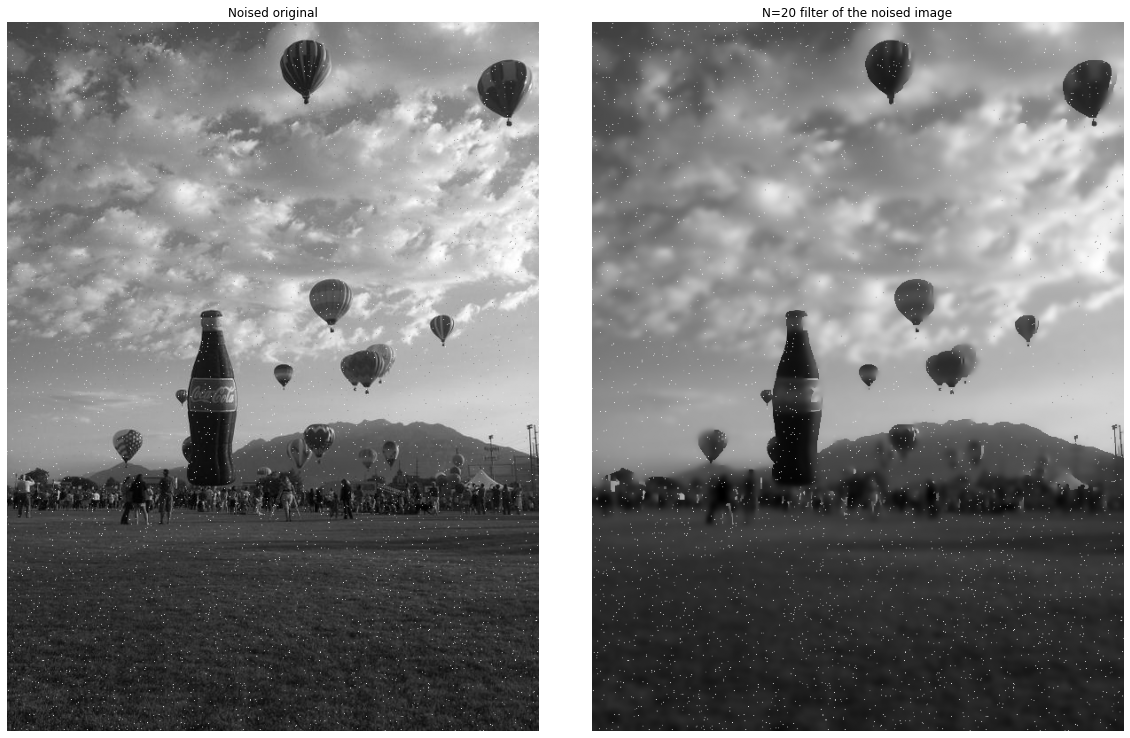

In [13]:
fig, ax = plt.subplots(1,2, figsize=(20,24))
ax[0].axis("off")
ax[0].imshow(image, cmap=cm.gray)
ax[0].set_title("Noised original")
ax[1].axis("off")
ax[1].imshow(U20, cmap=cm.gray)
ax[1].set_title("N=20 filter of the noised image")
plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.show()

The anisotropic diffusion does not smooth out the noise because the diffusion is minimizes blurring around the sharp edges of the image.

## Minimum bias (optional)

Anisotropic diffusion can also smear edges between regions with only small differences between them; decreasing $\sigma$ helps somewhat, but it won't remove random static spread throughout the image. A *minimum-biased* filter instead changes each pixel according to whether any of its neighbors have roughly the same value: in place of $g$, use the average of the two smallest differences between the pixel and its eight neighbors (using only the neighbors that exist along the boundaries). Pixels with a similar neighbor are left alone, while isolated pixels fade toward their surroundings. The scheme isn't symmetric like the first one, but with $\lambda \le \frac14$ and pixel values scaled to $[0,1]$ it stays within its minimum and maximum bounds. In the spec's example, 100000 random color values of the color balloon photo were changed, then cleaned with 300 iterations of a min-biased scheme and 8 more iterations of the first filter with $\lambda = .25$ and $\sigma = .04$.

## Problem 4: A minimum-biased filter (optional)

> ***Problem 4.** (Optional) Implement the minimum-biased finite difference scheme described above. Add noise to `balloons_color.jpg` using the provided code below, and clean it using your implementation. Show the original image, the noised image, and the cleaned image.
>
> ```python
> image = imread('balloons_color.jpg')
> x,y,z = image.shape
> for dim in xrange(z):
>     for i in xrange(x*y//100):
>         # Assign a random value to a random place
>         image[randint(x),randint(y),dim] = 127 + randint(127)
> ```
>
> Hint: Don't forget to rescale.

*Not completed.*